In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cuda")
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import optuna

import pyrite

optuna.logging.set_verbosity(optuna.logging.WARNING)
_ = pyrite.fetch_tables()
tables_ready = True

# Tuning CUDA execution

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/15-tuning-cuda-execution.py)

Find faster **execution settings** for one fixed simulation on the GPU in
front of you, check that they leave the spectrum unchanged, and see why the
winner belongs to that GPU. Execution settings decide how work is batched
on the device: electrons per transport launch, the continuation schedule
and its row quantum, and the CXR segment chunk. They are not physics, so
the tuner may only accept candidates whose spectra match the baseline.

This tutorial **needs an NVIDIA GPU**; on Molab, choose a GPU runtime. The
tuner, `TransportKernelTuning` and `KernelLattice` are experimental.
Timings depend on the device, driver, precision and the other work on the
machine.

In [ ]:
from pyrite import Scene
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Footprint, Slab

scene = Scene(
    Beam(energy_keV=30, transverse=PointSpot(), longitudinal=PointBunch()),
    Slab("hopg", thickness_ang=50_000, tilt_deg=45, footprint=Footprint(5, 5)),
    Detector(observation_angle_deg=90),
    numerics=Numerics(
        sampling=FixedSampling(cxr_electrons=8_192, brem_electrons=2_048),
        seed=7,
        energy_bins=EnergyBins(cxr=np.linspace(750, 1_000, 251)),
        cxr_reflections=CxrReflections(n_families=1),
    ),
)

In [ ]:
from pyrite.optimization import KernelLattice, tune_kernels

assert tables_ready
lattice = KernelLattice(
    electron_batch=(None, 2_048, 8_192),
    schedule=("full-history", "auto"),
    continuation_rows=(None, 128, 512),
    cxr_chunk=(None, 1_024, 4_096),
)
tuning = tune_kernels(scene, lattice, trials=16, warmups=1, repeats=3, rtol=1e-4, seed=11)
tuning.environment  # noqa: B018

In [ ]:
def describe(trial):
    t = trial.tuning.transport
    values = {
        "batch": t.electron_batch,
        "schedule": t.schedule,
        "rows": t.continuation_rows,
        "cxr chunk": trial.tuning.cxr_chunk,
    }
    return ", ".join(f"{k} {'default' if v is None else v}" for k, v in values.items())


_rows = ["| Trial | Settings | Median (s) | Outcome |", "|---:|---|---:|---|"]
_rows.append(
    f"| baseline | {describe(tuning.baseline)} | {tuning.baseline.median_s:.3f} | reference |"
)
for _trial in tuning.trials:
    if _trial.tuning is None or _trial.repeat_of is not None:
        continue  # invalid combination, or a resampled candidate reusing its first timing
    _time = "—" if _trial.median_s is None else f"{_trial.median_s:.3f}"
    _outcome = "accepted" if _trial.state == "complete" else f"rejected: {_trial.reason}"
    _rows.append(f"| {_trial.number} | {describe(_trial)} | {_time} | {_outcome} |")
_skipped = sum(t.tuning is None or t.repeat_of is not None for t in tuning.trials)
_fastest_base = min(tuning.baseline.samples_s)
_verdict = (
    "faster than every baseline repeat"
    if tuning.chosen.median_s < _fastest_base
    else "within the baseline's repeat spread, so treat it as a tie with the defaults"
)
mo.md(
    "\n".join(_rows)
    + f"\n\n{_skipped} trials were invalid combinations or resampled candidates that"
    " reused an earlier timing; they are not listed."
    + f"\n\n**Chosen:** {describe(tuning.chosen)} — {tuning.speedup:.2f}× the baseline"
    f" median, {_verdict}."
)

| Trial | Settings | Median (s) | Outcome |
|---:|---|---:|---|
| baseline | batch default, schedule default, rows default, cxr chunk default | 2.319 | reference |
| 0 | batch 8192, schedule auto, rows default, cxr chunk default | 2.478 | accepted |
| 1 | batch 2048, schedule auto, rows 512, cxr chunk 1024 | 35.519 | accepted |
| 2 | batch default, schedule auto, rows 128, cxr chunk 1024 | 35.410 | accepted |
| 3 | batch 8192, schedule full-history, rows default, cxr chunk default | 2.213 | accepted |
| 6 | batch 2048, schedule full-history, rows default, cxr chunk default | 2.588 | accepted |
| 8 | batch 2048, schedule auto, rows 512, cxr chunk 4096 | 10.211 | accepted |
| 9 | batch default, schedule auto, rows 512, cxr chunk default | 2.589 | accepted |
| 15 | batch default, schedule full-history, rows default, cxr chunk 1024 | 35.193 | accepted |

8 trials were invalid combinations or resampled candidates that reused an earlier timing; they are not listed.

**Chosen:** batch 8192, schedule full-history, rows default, cxr chunk default — 1.05× the baseline median, faster than every baseline repeat.

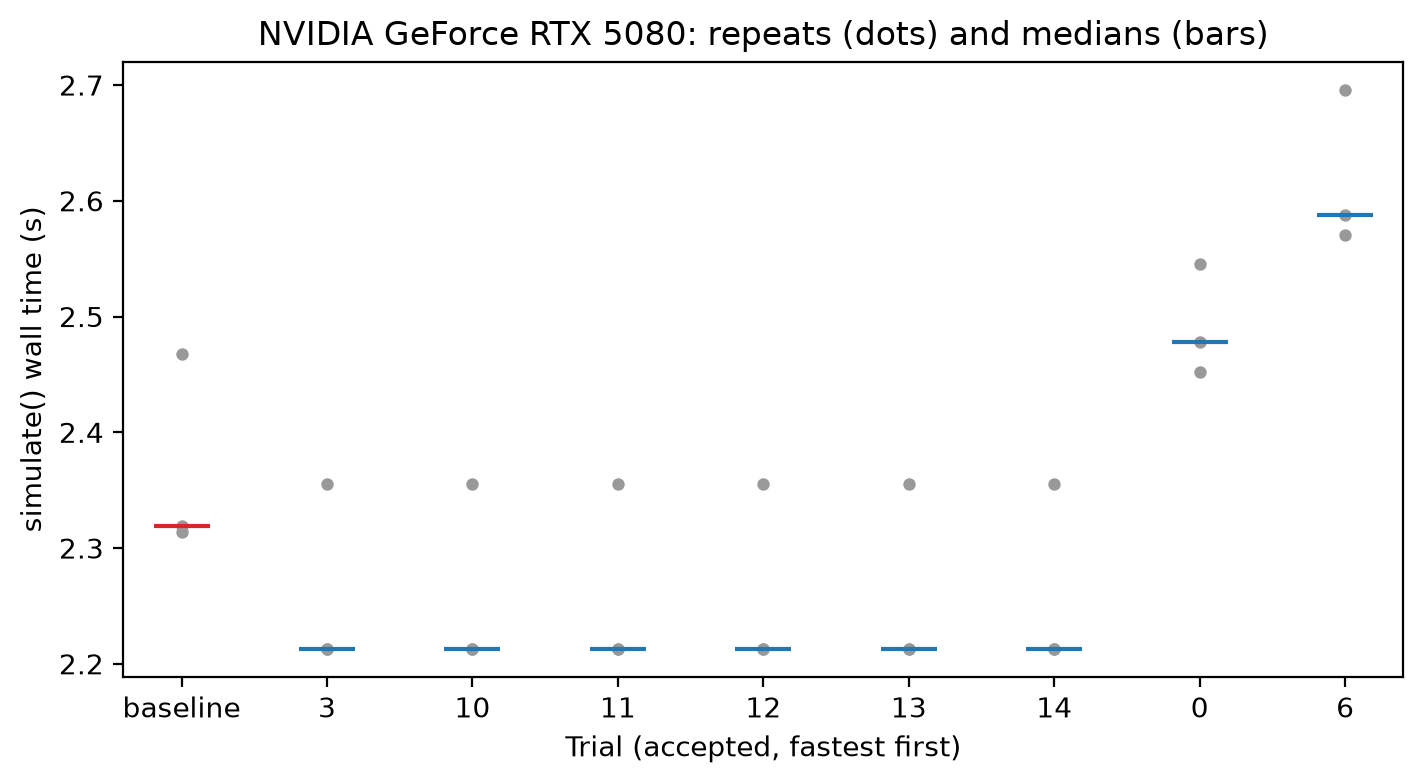

In [ ]:
_done = sorted((t for t in tuning.trials if t.state == "complete"), key=lambda t: t.median_s)
_shown = [tuning.baseline, *_done[:8]]
fig_timing, _ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
for _i, _trial in enumerate(_shown):
    _samples = np.asarray(_trial.samples_s)
    _ax.scatter(np.full(_samples.size, _i), _samples, color="0.6", s=12)
    _ax.scatter(_i, np.median(_samples), color="C3" if _i == 0 else "C0", marker="_", s=400)
_ax.set(
    xticks=range(len(_shown)),
    xticklabels=["baseline", *(str(t.number) for t in _shown[1:])],
    xlabel="Trial (accepted, fastest first)",
    ylabel="simulate() wall time (s)",
    title=f"{tuning.environment.get('device', 'GPU')}: repeats (dots) and medians (bars)",
)
fig_timing  # noqa: B018

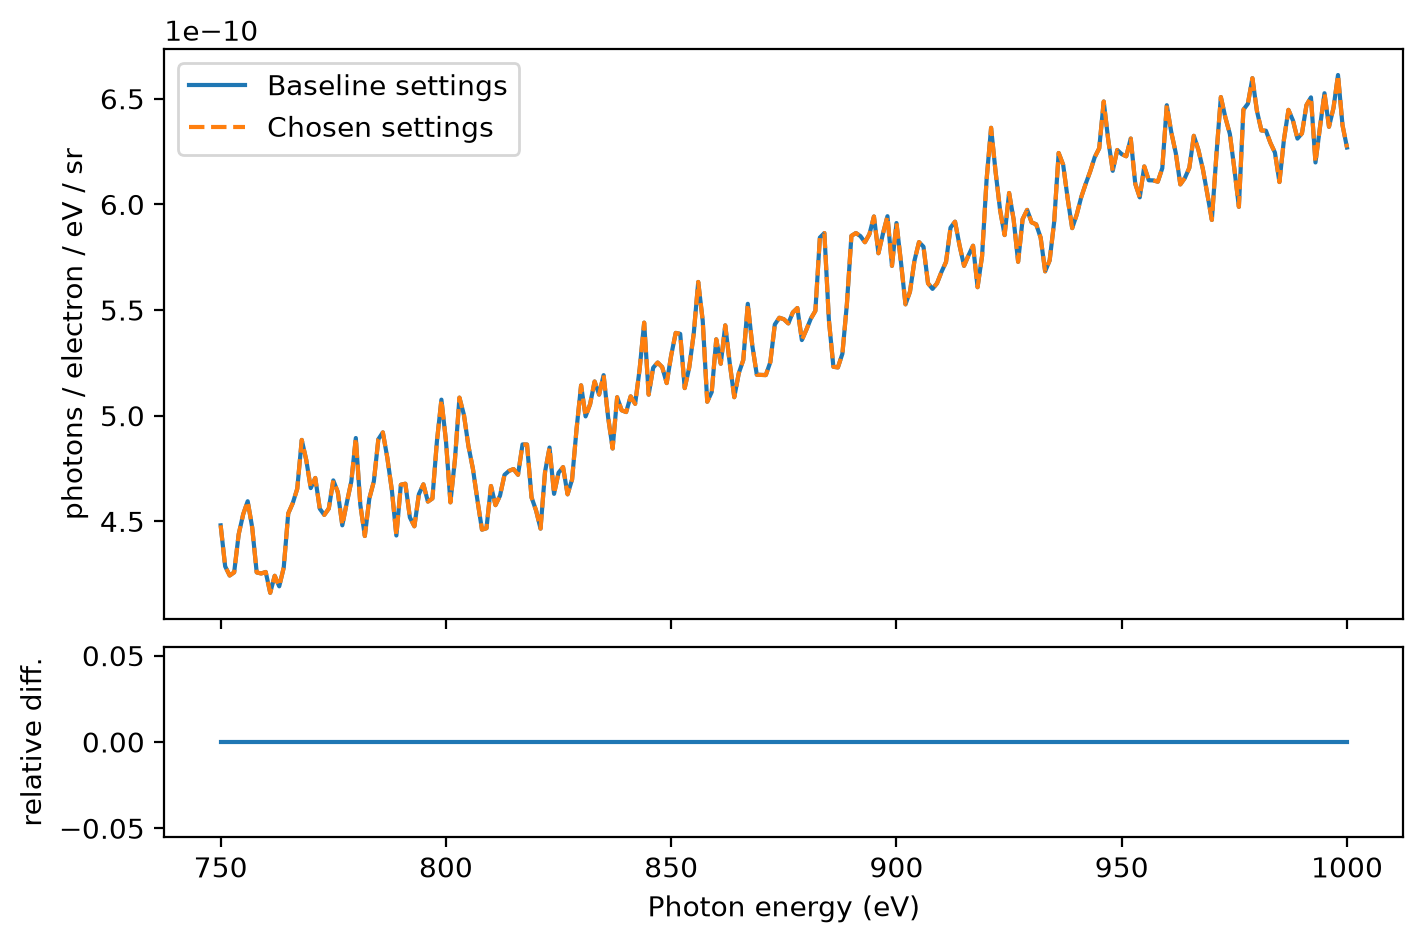

In [ ]:
baseline_result = pyrite.simulate(scene)
tuned_result = pyrite.simulate(scene, numerics=scene.numerics.with_kernel_tuning(tuning.best))
_energy = baseline_result.cxr.incoherent.photon_energy_eV
_base = baseline_result.cxr.incoherent.density
_tuned = tuned_result.cxr.incoherent.density
assert np.array_equal(_energy, tuned_result.cxr.incoherent.photon_energy_eV)
assert np.allclose(_tuned, _base, rtol=1e-4, atol=1e-12)
_floor = 1e-6 * np.abs(_base).max()
_relative = (_tuned - _base) / np.maximum(np.abs(_base), _floor)

fig_check, (_top, _bottom) = plt.subplots(
    2, 1, figsize=(7, 4.6), sharex=True, layout="constrained", height_ratios=(3, 1)
)
_top.plot(_energy, _base, label="Baseline settings")
_top.plot(_energy, _tuned, "--", label="Chosen settings")
_top.set(ylabel="photons / electron / eV / sr")
_top.legend()
_bottom.plot(_energy, _relative)
_bottom.set(xlabel="Photon energy (eV)", ylabel="relative diff.")
fig_check  # noqa: B018

In [ ]:
# Measurements recorded by this notebook on other GPUs (same scene, lattice and seed).
recorded = {
    "NVIDIA GeForce RTX 5080": {
        "baseline_s": 2.298,
        "chosen": "batch 8192, schedule full-history, rows default, cxr chunk default",
        "speedup": 1.06,
    },
}
_device = tuning.environment.get("device", "unknown GPU")
_rows = ["| GPU | Baseline median (s) | Chosen settings | Speedup |", "|---|---:|---|---:|"]
for _name, _run in recorded.items():
    if _name == _device:
        continue
    _rows.append(
        f"| {_name} (recorded) | {_run['baseline_s']:.3f} | {_run['chosen']} | {_run['speedup']:.2f}× |"
    )
_rows.append(
    f"| **{_device}** (this run) | {tuning.baseline.median_s:.3f} | {describe(tuning.chosen)} "
    f"| {tuning.speedup:.2f}× |"
)
mo.md("\n".join(_rows))

| GPU | Baseline median (s) | Chosen settings | Speedup |
|---|---:|---|---:|
| **NVIDIA GeForce RTX 5080** (this run) | 2.319 | batch 8192, schedule full-history, rows default, cxr chunk default | 1.05× |

Each trial ran `simulate()` in its **own process** with an explicit CUDA
backend. One untimed call absorbed kernel compilation, then three timed
calls gave the median. A candidate was accepted only if its photon-energy
grids matched the baseline exactly and its spectra agreed within
`rtol=1e-4`. Batch, schedule and row quantum reproduce the transport bit
for bit; the CXR chunk changes only the order of floating-point sums. The
tolerance is a tuning guard, not scientific validation.

**Read the timings against their spread.** A winner whose median lies
inside the baseline's repeats is a tie: the defaults were already right
for this workload on this device. In the recorded RTX 5080 run, transport
batch and schedule moved the median by under 10%, close to the repeat
spread. The one large effect was a small CXR chunk: 1,024 segments per
chunk ran about 15× slower than the default, and 4,096 about 4×.
Execution settings mostly need tuning to avoid a bad choice, not to find a
dramatic gain.

**The winner is specific to the GPU that measured it.** The comparison
table lists recorded runs of this notebook next to this run. A large
workstation GPU such as an RTX Pro 6000 has more memory and multiprocessors
than an RTX 5080, so its best batch and chunk need not match. Run the
notebook on that device, for example on a Molab GPU runtime, before
reusing a winner there. Apply a chosen setting with
`numerics.with_kernel_tuning(...)` in a new process, as the check above
does.

The scene uses 8,192 CXR and 2,048 bremsstrahlung Monte Carlo histories.
These are sample counts, not a physical beam current, and enough for `auto`
to consider continuation scheduling. The lattice tunes only execution
settings; it never changes the beam, target, physics models or seed. CXR
reduction launch geometry is not in the lattice: benchmarks on the RTX 5080
found no launch setting that beat the defaults, because the bin-mean
reduction itself dominates that cost.

## Continue learning

The [CUDA execution tuning how-to](../../guides/batch-chunk-tuning.md) applies a
winner and covers the CLI and Molab runs; the
[execution and acceleration explanation](../../computation/execution-and-acceleration.md)
describes each control and its defaults. The
[experimental API reference](../../reference/python-api/experimental.md#cuda-execution-tuning)
lists `tune_kernels`, `KernelLattice` and `TransportKernelTuning`.

{download}`Download canonical Marimo notebook <../15-tuning-cuda-execution.py>`